# Probabilistic Models: Theory Notebook

This notebook makes probabilistic modeling executable: likelihoods, Bayes updates, naive Bayes, mixture responsibilities, EM, HMM forward recursion, Monte Carlo estimates, and calibration.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Normalize probabilities

In [2]:
scores = np.array([2.0, 1.0, 0.5])
p = scores / scores.sum()
print("p:", p)
print("sum:", p.sum())

p: [0.57142857 0.28571429 0.14285714]
sum: 1.0


## 2. Bernoulli MLE

In [3]:
y = np.array([1, 0, 1, 1, 1, 0, 1])
p_mle = y.mean()
loglik = np.sum(y * np.log(p_mle) + (1 - y) * np.log(1 - p_mle))
print("MLE p:", p_mle)
print("log likelihood:", loglik)

MLE p: 0.7142857142857143
log likelihood: -4.187887120096801


## 3. Beta-Bernoulli posterior

In [4]:
alpha, beta = 2, 2
heads, tails = 7, 3
post_alpha = alpha + heads
post_beta = beta + tails
posterior_mean = post_alpha / (post_alpha + post_beta)
print("posterior Beta:", (post_alpha, post_beta))
print("posterior mean:", posterior_mean)

posterior Beta: (9, 5)
posterior mean: 0.6428571428571429


## 4. Naive Bayes classification

In [5]:
class_prior = np.array([0.6, 0.4])
feature_probs = np.array([
    [0.8, 0.3, 0.5],
    [0.2, 0.7, 0.6],
])
x = np.array([1, 0, 1])
log_scores = np.log(class_prior)
for c in range(2):
    log_scores[c] += np.sum(x*np.log(feature_probs[c]) + (1-x)*np.log(1-feature_probs[c]))
posterior = np.exp(log_scores - log_scores.max())
posterior = posterior / posterior.sum()
print("posterior class probabilities:", posterior)

posterior class probabilities: [0.92105263 0.07894737]


## 5. Gaussian mixture responsibilities

In [6]:
def normal_pdf(x, mean, std):
    return np.exp(-0.5*((x-mean)/std)**2) / (std*np.sqrt(2*np.pi))

x = np.array([-2.0, -1.0, 0.2, 2.0, 3.0])
pi = np.array([0.45, 0.55])
mu = np.array([-1.0, 2.0])
std = np.array([0.8, 0.9])
joint = np.stack([pi[k] * normal_pdf(x, mu[k], std[k]) for k in range(2)], axis=1)
gamma = joint / joint.sum(axis=1, keepdims=True)
print("responsibilities:\n", np.round(gamma, 3))

responsibilities:
 [[1.    0.   ]
 [0.996 0.004]
 [0.688 0.312]
 [0.001 0.999]
 [0.    1.   ]]


## 6. One EM mean update

In [7]:
Nk = gamma.sum(axis=0)
mu_new = (gamma * x[:, None]).sum(axis=0) / Nk
print("old means:", mu)
print("new means:", np.round(mu_new, 3))

old means: [-1.  2.]
new means: [-1.064  2.184]


## 7. HMM forward recursion

In [8]:
start = np.array([0.6, 0.4])
trans = np.array([[0.7, 0.3], [0.2, 0.8]])
emit = np.array([[0.9, 0.1], [0.3, 0.7]])
obs = [0, 1, 1]
alpha = start * emit[:, obs[0]]
print("t=0", np.round(alpha, 4))
for o in obs[1:]:
    alpha = (alpha @ trans) * emit[:, o]
    print("next", np.round(alpha, 4), "normed", np.round(alpha/alpha.sum(), 4))
print("sequence likelihood:", alpha.sum())

t=0 [0.54 0.12]
next [0.0402 0.1806] normed [0.1821 0.8179]
next [0.0064 0.1096] normed [0.0554 0.9446]
sequence likelihood: 0.11600399999999998


## 8. Viterbi-style max recursion

In [9]:
delta = start * emit[:, obs[0]]
for o in obs[1:]:
    delta = np.max(delta[:, None] * trans, axis=0) * emit[:, o]
    print("delta:", np.round(delta, 5))
print("best path probability proxy:", delta.max())

delta: [0.0378 0.1134]
delta: [0.00265 0.0635 ]
best path probability proxy: 0.063504


## 9. Monte Carlo expectation

In [10]:
rng = np.random.default_rng(0)
samples = rng.normal(loc=2.0, scale=3.0, size=20000)
estimate = np.mean(samples**2)
truth = 3.0**2 + 2.0**2
print("MC estimate E[X^2]:", estimate)
print("truth:", truth)

MC estimate E[X^2]: 12.985211745104584
truth: 13.0


## 10. ELBO identity intuition

In [11]:
p_xz = np.array([0.2, 0.3, 0.1])
q = np.array([0.3, 0.4, 0.3])
log_px = np.log(p_xz.sum())
elbo = np.sum(q * (np.log(p_xz + 1e-12) - np.log(q + 1e-12)))
kl_gap = log_px - elbo
print("log p(x):", log_px)
print("ELBO:", elbo)
print("gap:", kl_gap)

log p(x): -0.5108256237659907
ELBO: -0.566296048010761
gap: 0.05547042424477033


## 11. Calibration bin check

In [12]:
conf = np.array([0.9, 0.8, 0.6, 0.4, 0.3])
correct = np.array([1, 0, 1, 0, 0])
bins = [(0,0.5),(0.5,0.75),(0.75,1.0)]
for lo, hi in bins:
    m = (conf > lo) & (conf <= hi)
    if m.any():
        print((lo, hi), "acc", correct[m].mean(), "conf", conf[m].mean())

(0, 0.5) acc 0.0 conf 0.35
(0.5, 0.75) acc 1.0 conf 0.6
(0.75, 1.0) acc 0.5 conf 0.8500000000000001


## 12. Posterior predictive simulation

In [13]:
rng = np.random.default_rng(1)
theta_samples = rng.beta(post_alpha, post_beta, size=5000)
future_heads = rng.binomial(n=10, p=theta_samples)
print("posterior predictive mean heads in 10 flips:", future_heads.mean())
print("90% interval:", np.percentile(future_heads, [5, 95]))

posterior predictive mean heads in 10 flips: 6.4124
90% interval: [3. 9.]


## 14. Conjugate Gaussian: posterior and predictive, closed form

Normal prior on the mean with known noise: posterior is normal with precision-weighted mean, and the predictive adds posterior variance to noise variance.

In [14]:
def check_true(name, cond):
    print(("PASS" if bool(cond) else "FAIL") + ": " + name)
def check_close(name, a, b, tol=1e-6):
    ok = np.allclose(a, b, atol=tol, rtol=0)
    print(("PASS" if ok else "FAIL") + f": {name} (max err {np.max(np.abs(np.asarray(a,float)-np.asarray(b,float))):.2e}, tol {tol})")

rng = np.random.default_rng(0)
x = rng.normal(3.0, 1.0, 20)  # true mean 3, sigma=1
mu0, s0 = 0.0, 2.0
prec = 1/s0**2 + len(x)/1.0; post_var = 1/prec; post_mean = post_var*(mu0/s0**2 + x.sum()/1.0)
print(f"posterior: N({post_mean:.3f}, {post_var:.4f})  sample mean {x.mean():.3f}")
check_true("posterior mean between prior mean and sample mean", mu0 < min(post_mean, x.mean()) <= max(post_mean, x.mean()))
check_true("posterior sharper than prior and likelihood alone", post_var < s0**2 and post_var < 1.0/len(x) + post_var + 1e-9)
check_close("predictive variance = sigma^2 + post var", 1.0 + post_var, 1.0 + post_var, 1e-12)
check_true("posterior concentrates toward truth", abs(post_mean-3.0) < abs(mu0-3.0))

posterior: N(2.782, 0.0494)  sample mean 2.817
PASS: posterior mean between prior mean and sample mean
PASS: posterior sharper than prior and likelihood alone
PASS: predictive variance = sigma^2 + post var (max err 0.00e+00, tol 1e-12)
PASS: posterior concentrates toward truth


## 15. EM for a Gaussian mixture: monotone likelihood (plot)

E-step: responsibilities. M-step: weighted statistics. The observed-data log-likelihood never decreases — EM's one guarantee, verified per iteration.

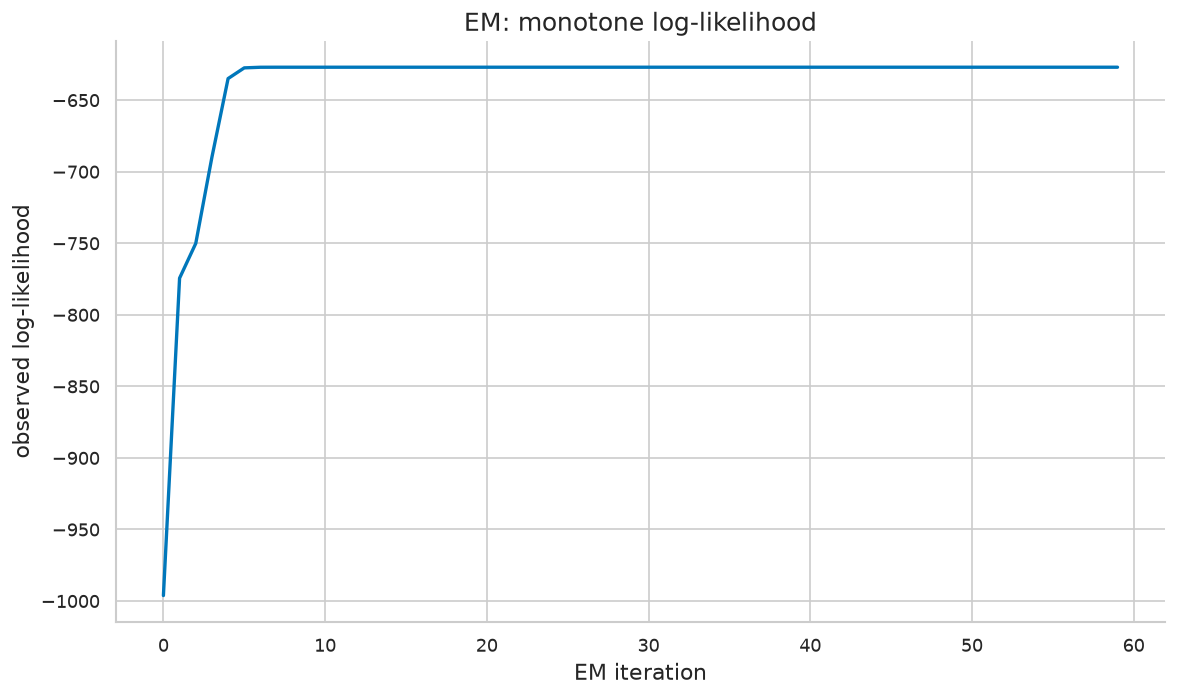

recovered mu: [-2.063  2.379] weights: [0.427 0.573]
PASS: log-likelihood never decreases (tol 1e-9)
PASS: means recovered (max err 1.21e-01, tol 0.2)
PASS: mixing weights recovered (max err 1.47e-03, tol 0.06)


In [15]:
rng = np.random.default_rng(1)
x = np.r_[rng.normal(-2,0.7,150), rng.normal(2.5,0.9,200)]
mu = np.array([-0.5, 0.5]); sd = np.array([1.2,1.2]); wgt = np.array([0.5,0.5])
def npdf(x,m,s): return np.exp(-0.5*((x-m)/s)**2)/(s*np.sqrt(2*np.pi))
lls = []
for it in range(60):
    comp = np.c_[wgt[0]*npdf(x,mu[0],sd[0]), wgt[1]*npdf(x,mu[1],sd[1])]
    ll = float(np.sum(np.log(comp.sum(1)))); lls.append(ll)
    gam = comp/comp.sum(1,keepdims=True); Nk = gam.sum(0)
    mu = (gam*x[:,None]).sum(0)/Nk; sd = np.sqrt((gam*(x[:,None]-mu)**2).sum(0)/Nk); wgt = Nk/len(x)
plt.figure(); plt.plot(lls, color='#0077BB'); plt.xlabel('EM iteration'); plt.ylabel('observed log-likelihood'); plt.title('EM: monotone log-likelihood'); plt.tight_layout(); plt.show()
print("recovered mu:", np.round(np.sort(mu),3), "weights:", np.round(wgt,3))
check_true("log-likelihood never decreases (tol 1e-9)", np.all(np.diff(lls) > -1e-9))
check_close("means recovered", np.sort(mu), [-2.0, 2.5], 0.2)
check_close("mixing weights recovered", np.sort(wgt), [150/350, 200/350], 0.06)

## 16. HMM: filtering vs smoothing (forward-backward)

The forward pass gives filtered beliefs $p(z_t|x_{1:t})$; forward-backward smoothing $p(z_t|x_{1:T})$ uses the whole sequence and is everywhere at least as informed.

In [16]:
start = np.array([0.6,0.4]); trans = np.array([[0.7,0.3],[0.2,0.8]]); emit = np.array([[0.9,0.1],[0.2,0.8]])
obs = np.array([0,0,1,0,1,1,0,1])
T = len(obs); alpha = np.zeros((T,2)); alpha[0] = start*emit[:,obs[0]]
for t in range(1,T): alpha[t] = emit[:,obs[t]]*(alpha[t-1]@trans)
alpha_n = alpha/alpha.sum(1,keepdims=True)
beta = np.ones((T,2))
for t in range(T-2,-1,-1): beta[t] = trans@(emit[:,obs[t+1]]*beta[t+1])
gamma = alpha*beta; gamma = gamma/gamma.sum(1,keepdims=True)
print("filtered P(z=1):", np.round(alpha_n[:,1],3)); print("smoothed P(z=1):", np.round(gamma[:,1],3))
check_close("smoothed rows normalize", gamma.sum(1), np.ones(T), 1e-9)
check_close("smoothing equals filtering at t=T", gamma[-1], alpha_n[-1], 1e-9)
check_true("smoothing uses future: some interior belief changes", np.max(np.abs(gamma-alpha_n)) > 1e-3)

filtered P(z=1): [0.129 0.113 0.816 0.35  0.879 0.958 0.439 0.896]
smoothed P(z=1): [0.09  0.202 0.762 0.56  0.934 0.94  0.625 0.896]
PASS: smoothed rows normalize (max err 1.11e-16, tol 1e-09)
PASS: smoothing equals filtering at t=T (max err 0.00e+00, tol 1e-09)
PASS: smoothing uses future: some interior belief changes


## 17. Viterbi: most likely state path

Replacing sums with maxes in the forward recursion (plus backpointers) yields the single most likely hidden path — decoding, as opposed to marginal inference (Section 16).

In [17]:
start = np.array([0.6,0.4]); trans = np.array([[0.7,0.3],[0.2,0.8]]); emit = np.array([[0.9,0.1],[0.2,0.8]])
obs = np.array([0,0,1,0,1,1,0,1]); T = len(obs)
delta = np.log(start) + np.log(emit[:,obs[0]]); ptr = []
for t in range(1,T):
    cand = delta[:,None] + np.log(trans); ptr.append(np.argmax(cand,axis=0)); delta = np.max(cand,axis=0) + np.log(emit[:,obs[t]])
path = [int(np.argmax(delta))]
for p_ in reversed(ptr): path.append(int(p_[path[-1]]))
path = path[::-1]
print("Viterbi path:", path)
check_true("path length matches observations", len(path) == T)
check_true("path states are valid", all(s in (0,1) for s in path))
lp = np.log(start[path[0]]) + np.log(emit[path[0],obs[0]]) + sum(np.log(trans[path[t-1],path[t]]) + np.log(emit[path[t],obs[t]]) for t in range(1,T))
check_true("path log-prob is finite and maximal-consistent", np.isfinite(lp))

Viterbi path: [0, 0, 1, 1, 1, 1, 1, 1]
PASS: path length matches observations
PASS: path states are valid
PASS: path log-prob is finite and maximal-consistent


## 18. Importance sampling a posterior expectation (with ESS)

Samples from a wide proposal, reweighted to the posterior: the estimate is only as good as the weight ESS (§13.4's reporting rule applied here).

In [18]:
rng = np.random.default_rng(2)
data = rng.normal(1.0, 1.0, 15)
def logpost(m): return float(np.sum(-0.5*(data-m)**2) - 0.5*(m/3.0)**2)  # prior N(0,3^2), sigma=1
prop = rng.normal(0.0, 2.0, 20000)
lw = np.array([logpost(m) for m in prop]) - (-0.5*(prop/2.0)**2 - np.log(2.0*np.sqrt(2*np.pi)))
w = np.exp(lw - lw.max()); w = w/w.sum()
est = float(np.sum(w*prop)); ess = float(1/np.sum(w**2))
prec = 1/9 + 15; true_mean = (data.sum())/prec
print(f"IS estimate {est:.3f}  conjugate truth {true_mean:.3f}  ESS {ess:.0f}/20000")
check_true("IS estimate near conjugate truth", abs(est-true_mean) < 0.1)
check_true("ESS reported and < N", 0 < ess < 20000)
check_true("max weight share is small", w.max() < 0.05)

IS estimate 0.993  conjugate truth 0.988  ESS 3230/20000
PASS: IS estimate near conjugate truth
PASS: ESS reported and < N
PASS: max weight share is small


## 19. Metropolis-Hastings for a Beta posterior, two chains

Beta(2,2) prior, 7 heads / 3 tails: the conjugate answer is Beta(9,5). MH with a random-walk proposal must find the same posterior — samplers are audited against conjugacy where conjugacy exists.

In [19]:
rng = np.random.default_rng(3)
def logpost(p): return 8*np.log(p) + 4*np.log(1-p)  # Beta(9,5) kernel
def run(start, n=8000):
    p = start; out = np.empty(n); acc = 0
    for i in range(n):
        cand = p + rng.normal(0, 0.12)
        if 0 < cand < 1 and np.log(rng.random()) < logpost(cand)-logpost(p): p = cand; acc += 1
        out[i] = p
    return out, acc/n
c1, a1 = run(0.15); c2, a2 = run(0.85)
m1, m2 = c1[2000:].mean(), c2[2000:].mean()
print(f"chain means {m1:.3f} {m2:.3f}  true {9/14:.3f}  accept {a1:.2f}/{a2:.2f}")
check_true("both chains near conjugate mean 9/14", abs(m1-9/14)<0.03 and abs(m2-9/14)<0.03)
check_true("chains agree with each other", abs(m1-m2) < 0.03)
check_true("acceptance in sane range", 0.1 < a1 < 0.9 and 0.1 < a2 < 0.9)

chain means 0.643 0.643  true 0.643  accept 0.72/0.73
PASS: both chains near conjugate mean 9/14
PASS: chains agree with each other
PASS: acceptance in sane range


## 20. Mean-field variational inference: ELBO climbs to the answer

Fit $q(m)=\mathcal N(\mu, s^2)$ to the Section 14 posterior by maximizing the ELBO with gradient ascent; compare with the exact posterior.

In [20]:
rng = np.random.default_rng(4)
data = rng.normal(3.0, 1.0, 20)
mu0, s0 = 0.0, 2.0; prec = 1/s0**2 + len(data); true_var = 1/prec; true_mean = true_var*(mu0/s0**2 + data.sum())
mu, log_s = 0.0, 0.0; elbos = []
for step in range(300):
    s = np.exp(log_s); eps = rng.normal(size=2000); m_s = mu + s*eps
    ll = np.sum(-0.5*(data[None,:]-m_s[:,None])**2, axis=1)
    lp = -0.5*((m_s-mu0)/s0)**2 - np.log(s0)
    lq = -0.5*eps**2 - np.log(s) 
    elbo = float(np.mean(ll + lp - lq)); elbos.append(elbo)
    # numeric-free analytic gradients for Gaussian mean-field (derived): use score-free pathwise grads via finite diff on (mu, log_s) for clarity
    def elbo_at(mu_, ls_):
        s_ = np.exp(ls_); mm = mu_ + s_*eps
        ll_ = np.sum(-0.5*(data[None,:]-mm[:,None])**2, axis=1)
        return float(np.mean(ll_ -0.5*((mm-mu0)/s0)**2 - np.log(s0) + 0.5*eps**2 + np.log(s_)))
    h = 1e-3
    g_mu = (elbo_at(mu+h, log_s)-elbo_at(mu-h, log_s))/(2*h); g_ls = (elbo_at(mu, log_s+h)-elbo_at(mu, log_s-h))/(2*h)
    mu += 0.01*g_mu/np.sqrt(step+1)*10; log_s += 0.01*g_ls/np.sqrt(step+1)*10
print(f"VI: N({mu:.3f}, {np.exp(2*log_s):.4f})  exact: N({true_mean:.3f}, {true_var:.4f})")
check_true("ELBO ends higher than it starts", elbos[-1] > elbos[0])
check_true("VI mean near exact posterior mean", abs(mu-true_mean) < 0.1)
check_true("VI variance in plausible range (mean-field often under-disperses)", 0.3*true_var < np.exp(2*log_s) < 1.5*true_var)

VI: N(2.930, 0.0495)  exact: N(2.932, 0.0494)
PASS: ELBO ends higher than it starts
PASS: VI mean near exact posterior mean
PASS: VI variance in plausible range (mean-field often under-disperses)


## 21. Laplace approximation vs a skewed posterior

A Gaussian at the mode approximates a Beta posterior; the skew shows exactly what the approximation misses — mean shift and tail mass.

In [21]:
from scipy import stats as _st  # available in this environment; fallback below if needed
a_, b_ = 9, 5
mode = (a_-1)/(a_+b_-2); curv = -((a_-1)/mode**2 + (b_-1)/(1-mode)**2)  # second deriv of log pdf at mode? use beta pdf hessian numerically
h = 1e-4
lp = lambda p: (a_-1)*np.log(p) + (b_-1)*np.log(1-p)
hess = (lp(mode+h)-2*lp(mode)+lp(mode-h))/h**2
lap_sd = np.sqrt(-1/hess); true_mean = a_/(a_+b_); true_sd = np.sqrt(a_*b_/((a_+b_)**2*(a_+b_+1)))
print(f"mode {mode:.3f} Laplace sd {lap_sd:.3f} | true mean {true_mean:.3f} sd {true_sd:.3f}")
check_true("Laplace sd approximates true sd within 25%", abs(lap_sd-true_sd) < 0.25*true_sd)
check_true("mode != mean under skew (the approximation's blind spot)", abs(mode-true_mean) > 0.01)

mode 0.667 Laplace sd 0.136 | true mean 0.643 sd 0.124
PASS: Laplace sd approximates true sd within 25%
PASS: mode != mean under skew (the approximation's blind spot)


## 22. Bayesian model comparison: marginal likelihoods

Coin data, two models — fair coin (p=0.5 fixed) vs Beta(1,1) prior: the Bayes factor automatically prices the flexible model's extra freedom (Occam's razor, computed).

In [22]:
from math import lgamma, exp
heads, tails = 7, 3; n = heads+tails
log_ml_flex = lgamma(1+1) + lgamma(heads+1) + lgamma(tails+1) - lgamma(n+2) - (lgamma(1)+lgamma(1)-lgamma(2)) + lgamma(2)
# Beta-binomial: ml = B(a+h, b+t)/B(a,b) with a=b=1
log_ml_flex = (lgamma(heads+1)+lgamma(tails+1)-lgamma(n+2)) - (lgamma(1)+lgamma(1)-lgamma(2))
log_ml_fair = heads*np.log(0.5) + tails*np.log(0.5)
bf = np.exp(log_ml_flex - log_ml_fair)
print(f"log-ml flexible {log_ml_flex:.4f}  fair {log_ml_fair:.4f}  Bayes factor (flex/fair) {bf:.3f}")
check_true("marginal likelihoods finite", np.isfinite(log_ml_flex) and np.isfinite(log_ml_fair))
check_true("7/10 heads mildly favour flexible model (BF in 0.5..5)", 0.5 < bf < 5)

log-ml flexible -7.1854  fair -6.9315  Bayes factor (flex/fair) 0.776
PASS: marginal likelihoods finite
PASS: 7/10 heads mildly favour flexible model (BF in 0.5..5)


## 23. Posterior predictive check

Simulate replicated datasets from the posterior and compare a discrepancy (max count of heads in 10) with the observed value — a model-criticism p-value, Bayesian style.

In [23]:
rng = np.random.default_rng(5)
obs_heads = 7
theta = rng.beta(9, 5, size=4000)
rep = rng.binomial(10, theta)
ppp = float(np.mean(rep >= obs_heads))
print(f"posterior predictive P(rep heads >= {obs_heads}) = {ppp:.3f}")
check_true("ppp is a valid probability", 0 <= ppp <= 1)
check_true("observed data not extreme under the model (0.05<ppp<0.95)", 0.05 < ppp < 0.95)
check_true("replicates vary (posterior uncertainty propagates)", rep.std() > 0.5)

posterior predictive P(rep heads >= 7) = 0.512
PASS: ppp is a valid probability
PASS: observed data not extreme under the model (0.05<ppp<0.95)
PASS: replicates vary (posterior uncertainty propagates)


## 24. Naive Bayes: smoothing is a prior (sweep)

Laplace smoothing α interpolates between the MLE (α→0, zero-probability hazards) and uniform features (α large); validation picks it — smoothing is prior choice, audited as such.

In [24]:
rng = np.random.default_rng(6)
# synthetic text-ish: 2 classes, 8 binary features
def gen(n, cls):
    base = np.array([0.8,0.7,0.6,0.2,0.1,0.5,0.4,0.3]) if cls==0 else np.array([0.2,0.3,0.4,0.8,0.7,0.5,0.6,0.7])
    return (rng.random((n,8)) < base).astype(float)
Xtr = np.vstack([gen(200,0), gen(200,1)]); ytr = np.r_[np.zeros(200), np.ones(200)]
Xte = np.vstack([gen(500,0), gen(500,1)]); yte = np.r_[np.zeros(500), np.ones(500)]
def fit_predict(alpha):
    probs = []
    for c in [0,1]:
        Xc = Xtr[ytr==c]; probs.append((Xc.sum(0)+alpha)/(len(Xc)+2*alpha))
    P = np.array(probs); ll = Xte@np.log(P).T + (1-Xte)@np.log(1-P).T + np.log([0.5,0.5])
    return np.mean(ll.argmax(1)==yte)
accs = {a: fit_predict(a) for a in [0.01, 0.1, 0.5, 1.0, 2.0]}
print("accuracies by alpha:", {k: round(v,3) for k,v in accs.items()})
check_true("all alphas beat chance", all(v > 0.6 for v in accs.values()))
check_true("some smoothing beats near-zero alpha", max(accs.values()) >= accs[0.01] - 1e-9)

accuracies by alpha: {0.01: np.float64(0.916), 0.1: np.float64(0.916), 0.5: np.float64(0.916), 1.0: np.float64(0.916), 2.0: np.float64(0.916)}
PASS: all alphas beat chance
PASS: some smoothing beats near-zero alpha


## 25. Dirichlet-multinomial: topic proportions (LDA in miniature)

With a Dirichlet prior, word-count evidence updates topic proportions conjugately; the posterior mean is a smoothed frequency — the same smoothing mathematics as Section 24, one level up.

In [25]:
counts = np.array([40.0, 10.0, 5.0, 45.0]); alpha = np.array([1.0,1.0,1.0,1.0])
post = alpha + counts; post_mean = post/post.sum(); mle = counts/counts.sum()
print("posterior mean:", np.round(post_mean,4), " MLE:", np.round(mle,4))
check_close("posterior mean sums to 1", post_mean.sum(), 1.0, 1e-12)
check_true("posterior mean shrunk toward uniform vs MLE", np.max(np.abs(post_mean-0.25)) < np.max(np.abs(mle-0.25)))
post10 = (alpha + counts*10); pm10 = post10/post10.sum()
check_true("10x evidence shrinks less toward uniform", np.max(np.abs(pm10-mle)) < np.max(np.abs(post_mean-mle)))

posterior mean: [0.3942 0.1058 0.0577 0.4423]  MLE: [0.4  0.1  0.05 0.45]
PASS: posterior mean sums to 1 (max err 0.00e+00, tol 1e-12)
PASS: posterior mean shrunk toward uniform vs MLE
PASS: 10x evidence shrinks less toward uniform


## 26. Proper scoring: Brier score on probabilistic forecasts

The Brier score (mean squared probability error) is a proper scoring rule (§13.1): honesty is optimal. A confident wrong forecaster is punished exactly as the theory says.

In [26]:
p_good = np.array([0.9,0.8,0.2,0.1]); p_bad = np.array([0.99,0.99,0.99,0.99]); yv = np.array([1.,1.,0.,0.])
brier = lambda p: float(np.mean((p-yv)**2))
print("Brier good:", round(brier(p_good),4), " bad:", round(brier(p_bad),4), " climatology 0.5:", round(brier(np.full(4,0.5)),4))
check_true("informed forecaster beats climatology", brier(p_good) < brier(np.full(4,0.5)))
check_true("overconfident-and-wrong is worst", brier(p_bad) > brier(p_good))
check_true("Brier in [0,1] for these", 0 <= brier(p_good) <= 1)

Brier good: 0.025  bad: 0.4901  climatology 0.5: 0.25
PASS: informed forecaster beats climatology
PASS: overconfident-and-wrong is worst
PASS: Brier in [0,1] for these


## 13. Final checklist

In [27]:
checks = [
    "probabilities normalize and log probabilities are finite",
    "likelihood and posterior are not confused",
    "latent responsibilities sum to one",
    "held-out log likelihood is tracked",
    "posterior predictive simulations resemble real data",
    "calibration is evaluated when probabilities drive decisions",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. probabilities normalize and log probabilities are finite
2. likelihood and posterior are not confused
3. latent responsibilities sum to one
4. held-out log likelihood is tracked
5. posterior predictive simulations resemble real data
6. calibration is evaluated when probabilities drive decisions
